# 02 Reproduce the paper's 1D position search (synthetic target)

The paper finds the x position of a sphere by inverse simulation (smoothed gradients from repeated simulations, `optimisation.run_optimization`). Without the IEEE DataPort files we cannot use the real measurement, so the target is a simulated sphere at the measured position 1 (`sparams.measured_sphere_pos[1]`, radius 20 mm). Hyper parameters are copied from the authors' `notebooks/OptimizePar.ipynb`. If the real data folder `InverseThzSim/data/rdm/real/calibrated64` exists, the last cell also runs the real case.

In [1]:
%run ./00_common.ipynb

C:\Users\Rey\anaconda3\envs\kolb\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


PROJECT  : C:\Users\Rey\Documents\Kolb_Radar_Project
FAKE_MODE: False
[mitsuba] Warning: Couldn't import the ipywidgets package. Installing this package is required for the system to properly log messages and print in Jupyter notebooks!


torch device: cuda
mitsuba variant: cuda_ad_rgb


Switched off Tx:  2
Switched off Rx:  10
torch 2.5.1+cu121 | device cuda
common ready


In [2]:
pos1 = sparams.measured_sphere_pos[1]
gt = np.array([pos1[0], pos1[1], pos1[2], 0.02], dtype=np.float32)
res = run_inverse_1d(gt, x_init=0.0, verbose=True)
print({k: v for k, v in res.items() if k != 'history_mm'})
save_json(res, '02_reproduce_1d_synthetic.json')
log(f"02 synthetic reproduce: final error {res['final_err_mm']:.2f} mm, iterations to 1 mm: {res['iters_to_tol']}, {res['seconds']:.0f} s")

iter 1: x=-0.02000  err=87.75 mm  loss=1.344e+04


iter 2: x=-0.03535  err=72.40 mm  loss=1.322e+04


iter 3: x=-0.05147  err=56.28 mm  loss=1.283e+04


iter 4: x=-0.06835  err=39.40 mm  loss=1.197e+04


iter 5: x=-0.08597  err=21.78 mm  loss=9317


...

iter 46: x=-0.10518  err=2.57 mm  loss=356.1


iter 47: x=-0.10679  err=0.96 mm  loss=51.68


iter 48: x=-0.10822  err=0.47 mm  loss=12.44


iter 49: x=-0.10899  err=1.24 mm  loss=86.42


iter 50: x=-0.10930  err=1.55 mm  loss=134.7
{'final_err_mm': 0.2220645546913147, 'iters_to_tol': 20, 'seconds': 2442.658029317856, 'x_init': 0.0, 'x_true': -0.10774999856948853}
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\02_reproduce_1d_synthetic.json
2026-10-26 19:31:56  02 synthetic reproduce: final error 0.22 mm, iterations to 1 mm: 20, 2443 s


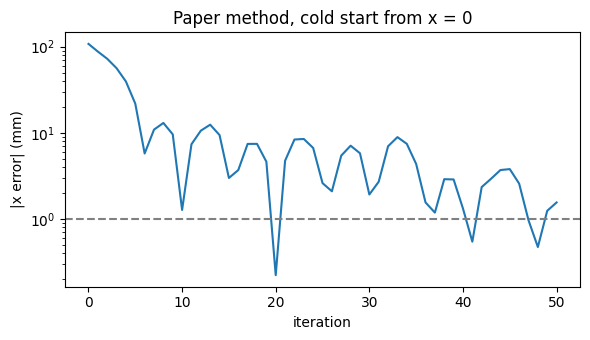

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 3.5)); plt.semilogy(res['history_mm']); plt.axhline(1.0, ls='--', c='grey')
plt.xlabel('iteration'); plt.ylabel('|x error| (mm)'); plt.title('Paper method, cold start from x = 0')
plt.tight_layout(); plt.savefig(FIGS / '02_reproduce_1d.png', dpi=120); plt.show()

In [4]:
# Optional: real measurement, only if the IEEE DataPort files were added under InverseThzSim/data/rdm/real/calibrated64
real_dir = REPO / 'data' / 'rdm' / 'real' / 'calibrated64'
if real_dir.exists():
    print('Real data found. Run the authors notebook OptimizePar.ipynb logic here (needs data/configurations/sphere_pos.json).')
else:
    print('No real data yet (IEEE DataPort). Skipping, this is expected tonight.')

No real data yet (IEEE DataPort). Skipping, this is expected tonight.
